# CLASS vs CosmoPower posteriors

Benchmark of the two pipelines on the same ΛCDM fit (one ω_m bin), on **both** mocks:

| mock (fake data) | fitted with CLASS | fitted with CosmoPower |
|---|---|---|
| CLASS mock (`with_class/model/lcdm.dat`) | `with_class/chains/model_lcdm__param_one_bin` | `with_cosmopower/chains/model_lcdm_from_class__param_one_bin` |
| CosmoPower mock (`with_cosmopower/model/lcdm.dat`) | `with_class/chains/model_lcdm_from_cosmopower__param_one_bin` | `with_cosmopower/chains/model_lcdm__param_one_bin` |

Both mocks are the same cosmology (ω_b 0.0224, h 0.674, τ 0.054, n_s 0.965, ln10¹⁰A_s 3.044, ω_m 0.15), made with the two codes.
On its own mock each code must recover the input exactly; the cross fits show what the code difference does to the parameters.

Run from the `omega_m/` root.

In [1]:
from pathlib import Path
import glob, re, ast
import numpy as np
import matplotlib.pyplot as plt
from getdist import loadMCSamples, plots

C = Path("with_class/chains")
P = Path("with_cosmopower/chains")

C2 = Path("with_class_mnu/chains")
P2 = Path("with_cp_lcdm/chains")

RUNS = {   # (mock, model) -> MontePython chain folder
    ("CLASS mock", "CLASS"):           C / "model_lcdm__param_one_bin",
    ("CLASS mock", "CosmoPower"):      P / "model_lcdm_from_class__param_one_bin",
    ("CosmoPower mock", "CLASS"):      C / "model_lcdm_from_cosmopower__param_one_bin",
    ("CosmoPower mock", "CosmoPower"): P / "model_lcdm__param_one_bin",
    # mnu physics (N_ur 2.0328 + 1x0.06 eV, HMcode): CP lcdm v1 emulators vs real CLASS. Only the cross fits exist so far.
    ("CLASS mnu mock", "CP lcdm"):     P2 / "model_lcdm_from_class_mnu__param_one_bin",   # mock: with_class_mnu/model/lcdm.dat
    ("CP lcdm mock", "CLASS mnu"):     C2 / "model_lcdm_from_cp_lcdm__param_one_bin",     # mock: with_cp_lcdm/model/lcdm.dat
}
TRUTH = {"omega_b": 0.0224, "h": 0.674, "tau_reio": 0.054, "n_s": 0.965,
         "ln10^{10}A_s": 3.044, "omega_m0": 0.15}       # input cosmology of both mocks
COLORS = {"CLASS": "#1A1A19", "CosmoPower": "#2A78D6", "CLASS mnu": "#1A1A19", "CP lcdm": "#2A78D6"}  # same colours as the slides
BURN_IN = 0.3
SAVE = True          # writes posteriors_benchmark_<mock>.pdf/png in omega_m/

In [2]:
LABELS = {"omega_b": r"\omega_b", "h": "h", "tau_reio": r"\tau_\mathrm{reio}", "n_s": "n_s",
          "ln10^{10}A_s": r"\ln(10^{10}A_s)", "H0": "H_0"}

def load(chain_dir, label):
    # MontePython folder -> GetDist samples (omega_b rescaled to physical, prior ranges from log.param)
    roots = [str(f)[:-len(".paramnames")] for f in Path(chain_dir).glob("*.paramnames")]
    roots = [r for r in roots if any(Path(c).stat().st_size > 0 for c in glob.glob(glob.escape(r) + "_[0-9]*.txt"))]
    root = max(roots, key=lambda r: len(glob.glob(glob.escape(r) + "_[0-9]*.txt")))   # most chain files
    s = loadMCSamples(root, settings={"ignore_rows": BURN_IN}, no_cache=True)

    logp = {}
    for name, row in re.findall(r"^data\.parameters\[['\"](.+?)['\"]\]\s*=\s*(\[.*?\])",
                                (Path(chain_dir) / "log.param").read_text(), re.M):
        logp[name] = ast.literal_eval(row)          # [mean, min, max, sigma, scale, role]
    ranges = {}
    for i, n in enumerate(s.getParamNames().list()):
        if n in logp:
            _, lo, hi, _, scale, role = logp[n]
            s.samples[:, i] *= scale
            if role != "derived":
                ranges[n] = (None if lo in (None, -1) else lo * scale, None if hi in (None, -1) else hi * scale)
    s.setRanges(ranges)
    for p in s.paramNames.names:
        p.label = LABELS.get(p.name, p.label)
        m = re.fullmatch(r"omega_m(\d+)", p.name)
        if m:
            p.label = rf"\omega_{{m,{m.group(1)}}}"
    s.updateBaseStatistics()
    s.label = label
    n_files = len(glob.glob(glob.escape(root) + "_[0-9]*.txt"))
    print(f"{label:<32} {n_files} chains  {root}")
    return s

samples = {key: load(d, f"{key[1]} model, {key[0]}") for key, d in RUNS.items()}
params = [n for n in TRUTH if all(n in s.getParamNames().list() for s in samples.values())]

with_class/chains/model_lcdm__param_one_bin/2026-10-09_100000__1.txt
with_class/chains/model_lcdm__param_one_bin/2026-10-09_100000__2.txt
with_class/chains/model_lcdm__param_one_bin/2026-10-09_100000__3.txt
with_class/chains/model_lcdm__param_one_bin/2026-10-09_100000__4.txt
with_class/chains/model_lcdm__param_one_bin/2026-10-09_100000__5.txt
with_class/chains/model_lcdm__param_one_bin/2026-10-09_100000__6.txt
with_class/chains/model_lcdm__param_one_bin/2026-10-09_100000__7.txt
with_class/chains/model_lcdm__param_one_bin/2026-10-09_100000__8.txt
Removed 0.3 as burn in
CLASS model, CLASS mock          8 chains  with_class/chains/model_lcdm__param_one_bin/2026-10-09_100000_
with_cosmopower/chains/model_lcdm_from_class__param_one_bin/2026-10-14_100000__1.txt
with_cosmopower/chains/model_lcdm_from_class__param_one_bin/2026-10-14_100000__2.txt
with_cosmopower/chains/model_lcdm_from_class__param_one_bin/2026-10-14_100000__3.txt
with_cosmopower/chains/model_lcdm_from_class__param_one_bin/2026

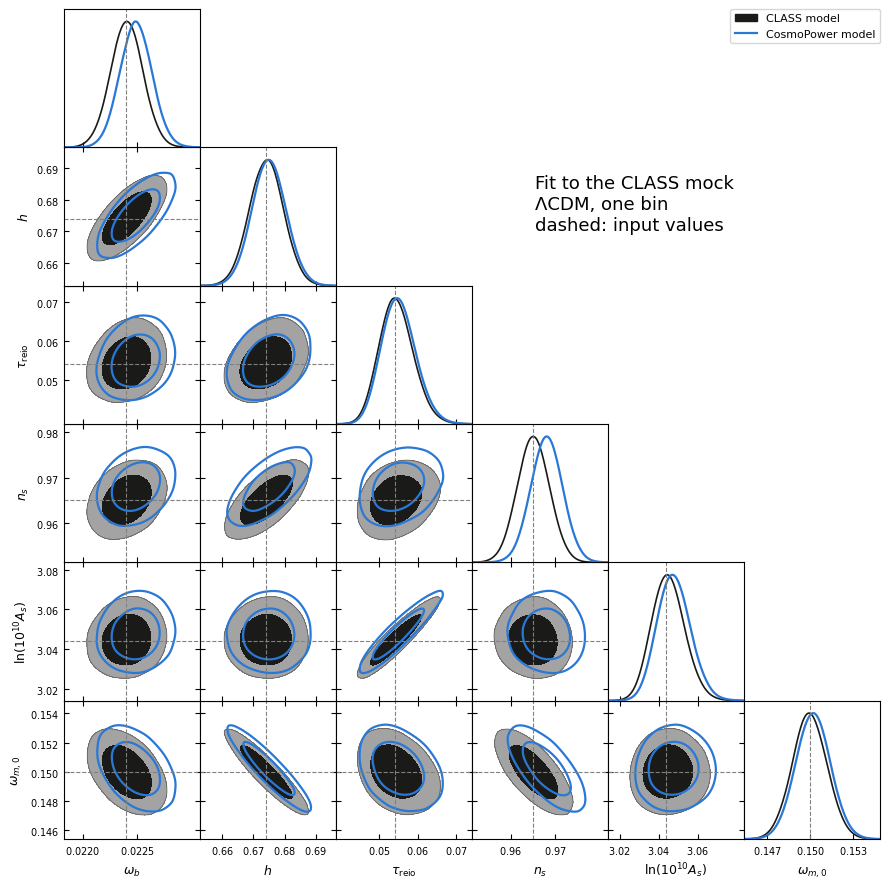

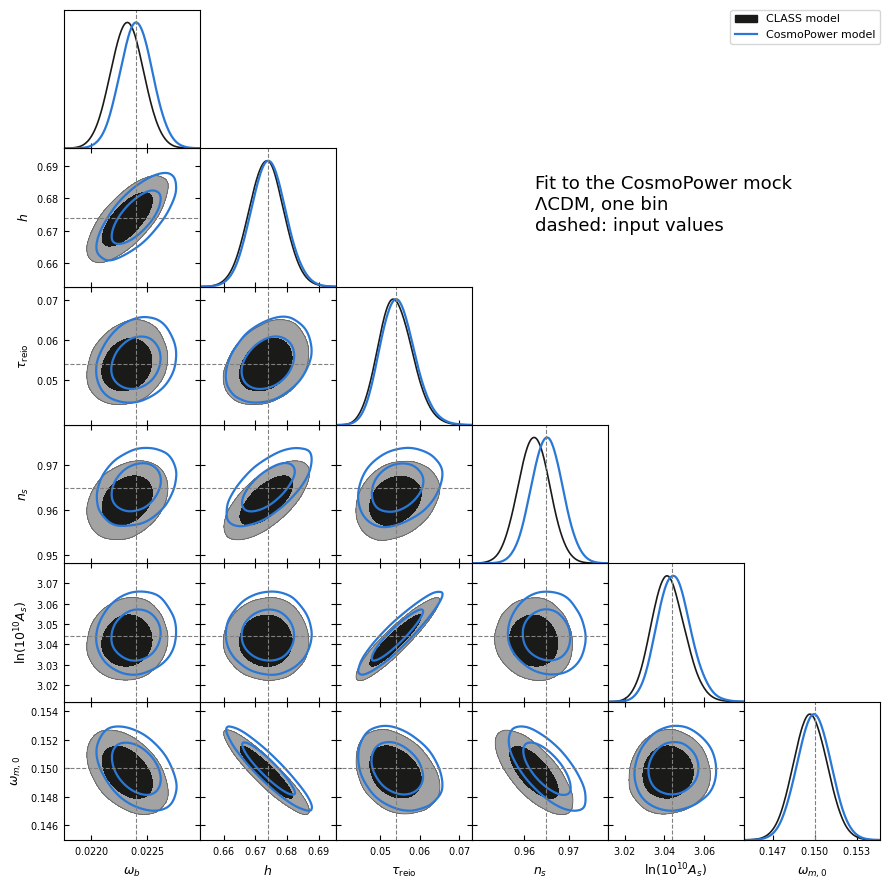

In [3]:
# One triangle plot per mock: CLASS model (filled) vs CosmoPower model (lines); grey lines = input values
for mock in ["CLASS mock", "CosmoPower mock"]:
    g = plots.get_subplot_plotter(width_inch=9)
    g.settings.legend_fontsize = 12
    g.settings.axes_labelsize = 13
    g.triangle_plot([samples[(mock, "CLASS")], samples[(mock, "CosmoPower")]], params,
                    filled=[True, False], contour_colors=[COLORS["CLASS"], COLORS["CosmoPower"]],
                    contour_lws=[1.2, 1.6], legend_labels=["CLASS model", "CosmoPower model"], legend_loc="upper right",
                    markers={p: TRUTH[p] for p in params}, marker_args={"color": "0.5", "lw": 0.8, "ls": "--"},
                    title_limit=0)
    g.fig.text(0.60, 0.80, f"Fit to the {mock}\n\u039bCDM, one bin\ndashed: input values", fontsize=13, va="top")
    if SAVE:
        tag = mock.split()[0].lower()
        g.export(f"posteriors_benchmark_{tag}_mock.pdf"); g.export(f"posteriors_benchmark_{tag}_mock.png")
    plt.show()

In [4]:
# Numbers: mean +- 68%, pull from the input value, and CosmoPower - CLASS on the same mock
def stats(s, n):
    m = s.getMargeStats().parWithName(n)
    return m.mean, m.err

rows = []
print(f"{'param':<14}{'mock':<17}{'CLASS model':>22}{'CosmoPower model':>22}{'CP-CLASS [sig]':>16}{'err CP/CLASS':>14}"
      f"{'CLASS pull':>12}{'CP pull':>10}")
for n in params:
    for mock in ["CLASS mock", "CosmoPower mock"]:
        mc, ec = stats(samples[(mock, "CLASS")], n)
        mp, ep = stats(samples[(mock, "CosmoPower")], n)
        shift = (mp - mc) / ec
        rows.append(dict(param=n, mock=mock, class_mean=mc, class_err=ec, cp_mean=mp, cp_err=ep, shift_sigma=shift,
                         err_ratio=ep / ec, class_pull=(mc - TRUTH[n]) / ec, cp_pull=(mp - TRUTH[n]) / ep))
        f = ".5f" if abs(mc) < 0.1 else ".4f"
        print(f"{n:<14}{mock:<17}{format(mc, f):>12} \u00b1 {format(ec, f):<8}{format(mp, f):>12} \u00b1 {format(ep, f):<8}"
              f"{shift:>+14.2f}{ep / ec:>14.2f}{(mc - TRUTH[n]) / ec:>+12.2f}{(mp - TRUTH[n]) / ep:>+10.2f}")

param         mock                        CLASS model      CosmoPower model  CP-CLASS [sig]  err CP/CLASS  CLASS pull   CP pull
omega_b       CLASS mock            0.02240 ± 0.00015      0.02249 ± 0.00015          +0.56          0.98       +0.03     +0.60
omega_b       CosmoPower mock       0.02232 ± 0.00015      0.02240 ± 0.00015          +0.55          0.98       -0.52     +0.03
h             CLASS mock             0.6742 ± 0.0055        0.6750 ± 0.0055           +0.15          1.00       +0.04     +0.19
h             CosmoPower mock        0.6735 ± 0.0055        0.6742 ± 0.0055           +0.12          1.00       -0.08     +0.04
tau_reio      CLASS mock            0.05454 ± 0.00441      0.05514 ± 0.00444          +0.14          1.01       +0.12     +0.26
tau_reio      CosmoPower mock       0.05391 ± 0.00433      0.05447 ± 0.00436          +0.13          1.01       -0.02     +0.11
n_s           CLASS mock             0.9651 ± 0.0036        0.9681 ± 0.0035           +0.83          0.9

How to read the table:
- **CP−CLASS [σ]**: difference of the two models' means on the same mock, in units of the CLASS 68% error. This is the code difference.
- **pull**: (mean − input)/σ. A code fitted to its *own* mock should give ≈ 0 for every parameter; a non-zero pull on the *other* code's mock is the bias from the code difference.
- **err CP/CLASS**: ratio of the two errors (≈ 1 means the codes give the same constraining power).

# mnu physics: CP lcdm emulator vs CLASS (m_nu = 0.06 eV, HMcode)

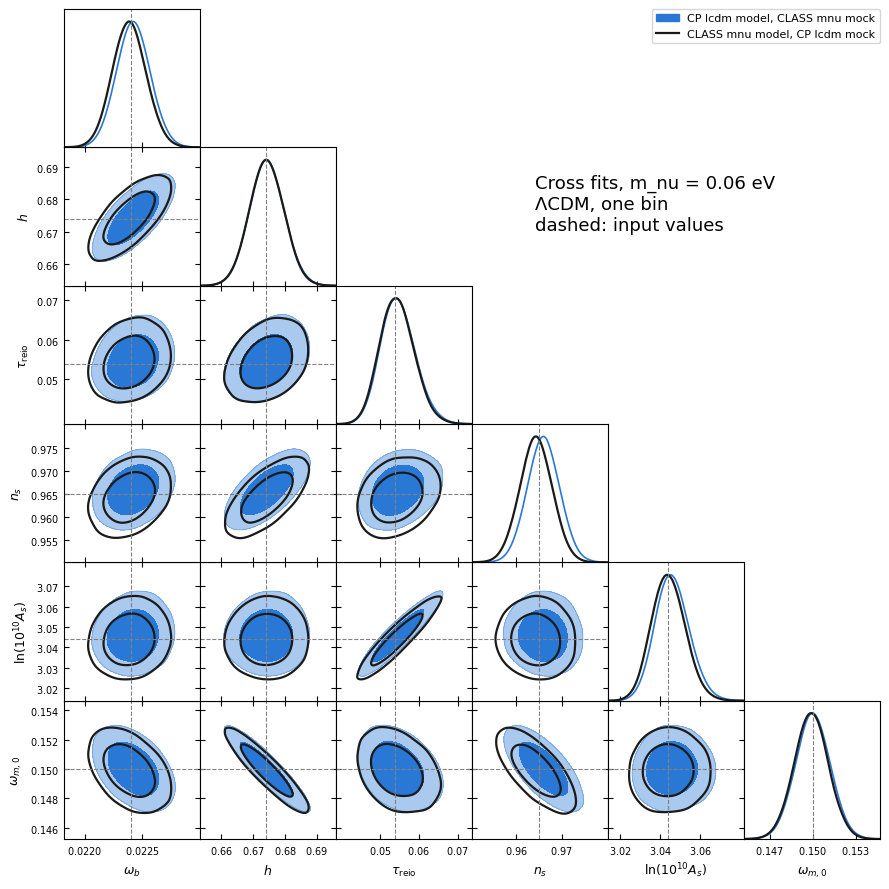

In [5]:
# Cross fits only: CP lcdm model on the CLASS mnu mock (filled) vs CLASS mnu model on the CP lcdm mock (lines).
# Same input cosmology, so each pulls away from the dashed input values by the code difference, in opposite directions.
cross = [samples[("CLASS mnu mock", "CP lcdm")], samples[("CP lcdm mock", "CLASS mnu")]]
g = plots.get_subplot_plotter(width_inch=9)
g.settings.legend_fontsize = 12
g.settings.axes_labelsize = 13
g.triangle_plot(cross, params,
                filled=[True, False], contour_colors=[COLORS["CP lcdm"], COLORS["CLASS mnu"]],
                contour_lws=[1.2, 1.6], legend_labels=["CP lcdm model, CLASS mnu mock", "CLASS mnu model, CP lcdm mock"],
                legend_loc="upper right",
                markers={p: TRUTH[p] for p in params}, marker_args={"color": "0.5", "lw": 0.8, "ls": "--"},
                title_limit=0)
g.fig.text(0.60, 0.80, "Cross fits, m_nu = 0.06 eV\n\u039bCDM, one bin\ndashed: input values", fontsize=13, va="top")
if SAVE:
    g.export("posteriors_benchmark_mnu_cross.pdf"); g.export("posteriors_benchmark_mnu_cross.png")
plt.show()

